# Role B — Tasks 3 and 5

## Fixed experimental protocol

CIFAR-10: 45,000 train / 5,000 validation images (stratified split seed 2223), with normalization fitted only on the training partition. The official 10,000-image test set is reserved for final evaluation. All six Task 3 runs use Tesla T4, FP32, seed 42, 30 epochs, batch 128, SGD momentum 0.9, learning rate 0.01, cosine scheduling, and no augmentation. Each configuration starts from fresh weights and processes 1,350,000 training examples. Best validation accuracy selects the checkpoint; lower validation CE breaks ties.

| Configuration | Convolution width | Dropout | Weight decay |
|---|---:|---:|---:|
| Reference | 1.0 | 0.5 | 5e-4 |
| Half width | 0.5 | 0.5 | 5e-4 |
| No dropout | 1.0 | 0 | 5e-4 |
| Moderate dropout | 1.0 | 0.25 | 5e-4 |
| No L2 | 1.0 | 0.5 | 0 |
| Weak L2 | 1.0 | 0.5 | 1e-4 |

Only one factor changes in each comparison. Width scaling changes the convolution channels while FC hidden dimensions stay 1024/512. Dropout follows the ReLU in both hidden FC layers. SGD decay applies to all parameters, including biases. Deterministic train_eval/val curves use evaluation mode and pure CE, excluding the regularization penalty. Training time includes both diagnostic evaluation passes.

## Task 5 protocol

Load the team's frozen AlexNet and ResNet baselines, source revision b1f9a7e; verify checkpoint identity, preprocessing and SHA256. Report clean accuracy, CE, macro F1, class metrics, row-normalized confusion matrices, and first five correct/incorrect predictions by image ID.

Untargeted FGSM operates in raw [0,1] pixels through differentiable preprocessing, with L-infinity epsilon = 0, 2/255, 4/255, 8/255. Every perturbation is checked against its budget. Adversarial accuracy uses all images; ASR uses only initially correct images. Model weights stay fixed. Uniform random noise is evaluated at the same budgets with per-image seeds. C's fixed rotation/translation/Gaussian corruptions are evaluated separately at their original severities and on the same image IDs.

The source archive contains the full Python implementation and frozen configurations. Datasets and weights are excluded from Git. Source/config/checkpoint hashes and true device metadata accompany all results.


In [2]:
from pathlib import Path
import zipfile, sys, subprocess, torch, os
ROOT = Path('/content/ScalableMlLab')
with zipfile.ZipFile('/content/role_b_inputs.zip') as archive:
    archive.extractall(ROOT)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'lab1/src'))
print('GPU:', torch.cuda.get_device_name(0), 'PyTorch:', torch.__version__)
subprocess.check_call([sys.executable, '-m', 'unittest', 'discover', '-s', 'lab1/tests', '-p', 'test_role_b.py', '-v'])
from run_role_b_experiments import main
main(['--stage', 'smoke', '--quiet'])


GPU: Tesla T4 PyTorch: 2.14.1+cu130


100%|██████████| 170M/170M [00:01<00:00, 92.2MB/s]


{"platform": "colab", "device_name": "Tesla T4", "precision": "fp32", "torch_version": "2.14.1+cu130", "cuda_version": "13.0"}
Training t3_alexnet_reference_s42: 128 images x 1 epochs


In [3]:
from io_utils import load_json
smoke = load_json(ROOT / 'lab1/results/smoke_role_b/smoke_fgsm.json')
assert smoke['num_samples'] == 64 and smoke['max_observed_linf'] <= 2/255 + 1e-6
print('Unit tests completed successfully; 128/64-image smoke test passed.')
print('Starting the predeclared six-run Task 3 matrix. Test evaluation follows all training.')
main(['--stage', 'all', '--quiet'])


Unit tests completed successfully; 128/64-image smoke test passed.
Starting the predeclared six-run Task 3 matrix. Test evaluation follows all training.
{"platform": "colab", "device_name": "Tesla T4", "precision": "fp32", "torch_version": "2.14.1+cu130", "cuda_version": "13.0"}
Training t3_alexnet_reference_s42: 45000 images x 30 epochs
Training t3_alexnet_width_half_s42: 45000 images x 30 epochs
Training t3_alexnet_dropout_zero_s42: 45000 images x 30 epochs
Training t3_alexnet_dropout_quarter_s42: 45000 images x 30 epochs
Training t3_alexnet_l2_zero_s42: 45000 images x 30 epochs
Training t3_alexnet_l2_weak_s42: 45000 images x 30 epochs
Final test t3_alexnet_reference_s42: 0.8266
Final test t3_alexnet_width_half_s42: 0.8052
Final test t3_alexnet_dropout_zero_s42: 0.7991
Final test t3_alexnet_dropout_quarter_s42: 0.8145
Final test t3_alexnet_l2_zero_s42: 0.8219
Final test t3_alexnet_l2_weak_s42: 0.8135
t2_alexnet_cifar_baseline_s42 fgsm eps=0.00000: acc=0.8214, ASR=0.0
t2_alexnet_cifar

,exp_id,name,width_mult,dropout,weight_decay,params,best_val_acc,best_val_ce,best_epoch,final_train_eval_acc,final_val_acc,training_sec,trained_samples,peak_gpu_mem_mb,device,test_acc,bs1_latency_ms
0,t3_alexnet_reference_s42,reference,1.0,0.50,0.0005,6976842,0.8346,0.886515,30,1.000000,0.8346,358.596,1350000,314.94,Tesla T4,0.8266,0.647171
1,t3_alexnet_width_half_s42,width_half,0.5,0.50,0.0005,3191722,0.8130,0.985985,29,0.999889,0.8128,175.935,1350000,160.59,Tesla T4,0.8052,0.660939
2,t3_alexnet_dropout_zero_s42,dropout_zero,1.0,0.00,0.0005,6976842,0.8046,1.134273,15,1.000000,0.8028,371.390,1350000,314.94,Tesla T4,0.7991,0.659253
3,t3_alexnet_dropout_quarter_s42,dropout_quarter,1.0,0.25,0.0005,6976842,0.8138,0.973340,21,1.000000,0.8126,370.438,1350000,314.94,Tesla T4,0.8145,0.639251
4,t3_alexnet_l2_zero_s42,l2_zero,1.0,0.50,0.0000,6976842,0.8314,1.064778,24,1.000000,0.8296,365.824,1350000,315.07,Tesla T4,0.8219,0.727297
5,t3_alexnet_l2_weak_s42,l2_weak,1.0,0.50,0.0001,6976842,0.8314,0.990880,23,1.000000,0.8280,367.689,1350000,314.94,Tesla T4,0.8135,0.661835


,exp_id,source_exp_id,accuracy,ce,macro_f1
0,t5_t2_alexnet_cifar_baseline_s42,t2_alexnet_cifar_baseline_s42,0.8214,0.931000,0.820482
1,t5_t2_resnet18_cifar_baseline_s42,t2_resnet18_cifar_baseline_s42,0.8702,0.435732,0.869897


,source_exp_id,num_samples,clean_accuracy,accuracy,clean_correct_count,successful_count,asr,method,targeted,norm,epsilon,max_observed_linf,ce,evaluation_time_sec,random_seed
0,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8214,8214,0,0.000000,fgsm,False,linf,0.000000,0.000000,0.931000,1.440110,NaN
1,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.4650,8214,3564,0.433893,fgsm,False,linf,0.007843,0.007843,4.415311,2.652829,NaN
2,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.2749,8214,5465,0.665327,fgsm,False,linf,0.015686,0.015686,8.474964,2.670277,NaN
3,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.1901,8214,6313,0.768566,fgsm,False,linf,0.031373,0.031373,13.324855,2.680068,NaN
4,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8214,8214,0,0.000000,random_linf,False,linf,0.000000,0.000000,0.931000,1.467030,2223.0
5,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8207,8214,26,0.003165,random_linf,False,linf,0.007843,0.007843,0.930377,1.527496,2223.0
6,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8207,8214,50,0.006087,random_linf,False,linf,0.015686,0.015686,0.931065,1.458540,2223.0
7,t2_alexnet_cifar_baseline_s42,10000,0.8214,0.8167,8214,137,0.016679,random_linf,False,linf,0.031373,0.031373,0.939469,1.447628,2223.0
8,t2_resnet18_cifar_baseline_s42,10000,0.8702,0.8702,8702,0,0.000000,fgsm,False,linf,0.000000,0.000000,0.435732,6.197688,NaN
9,t2_resnet18_cifar_baseline_s42,10000,0.8702,0.2834,8702,5868,0.674328,fgsm,False,linf,0.007843,0.007843,4.406083,13.360838,NaN


t3_capacity.png


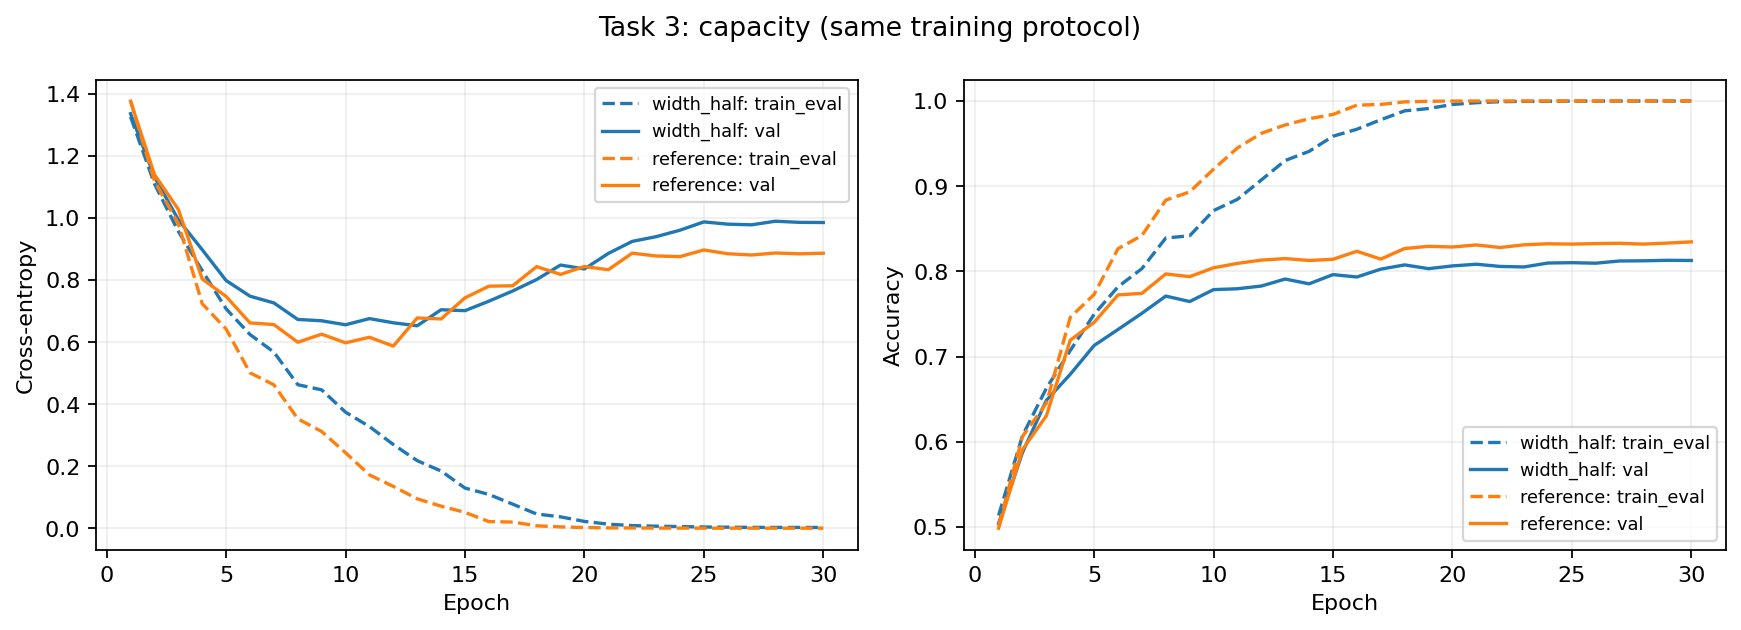

t3_dropout.png


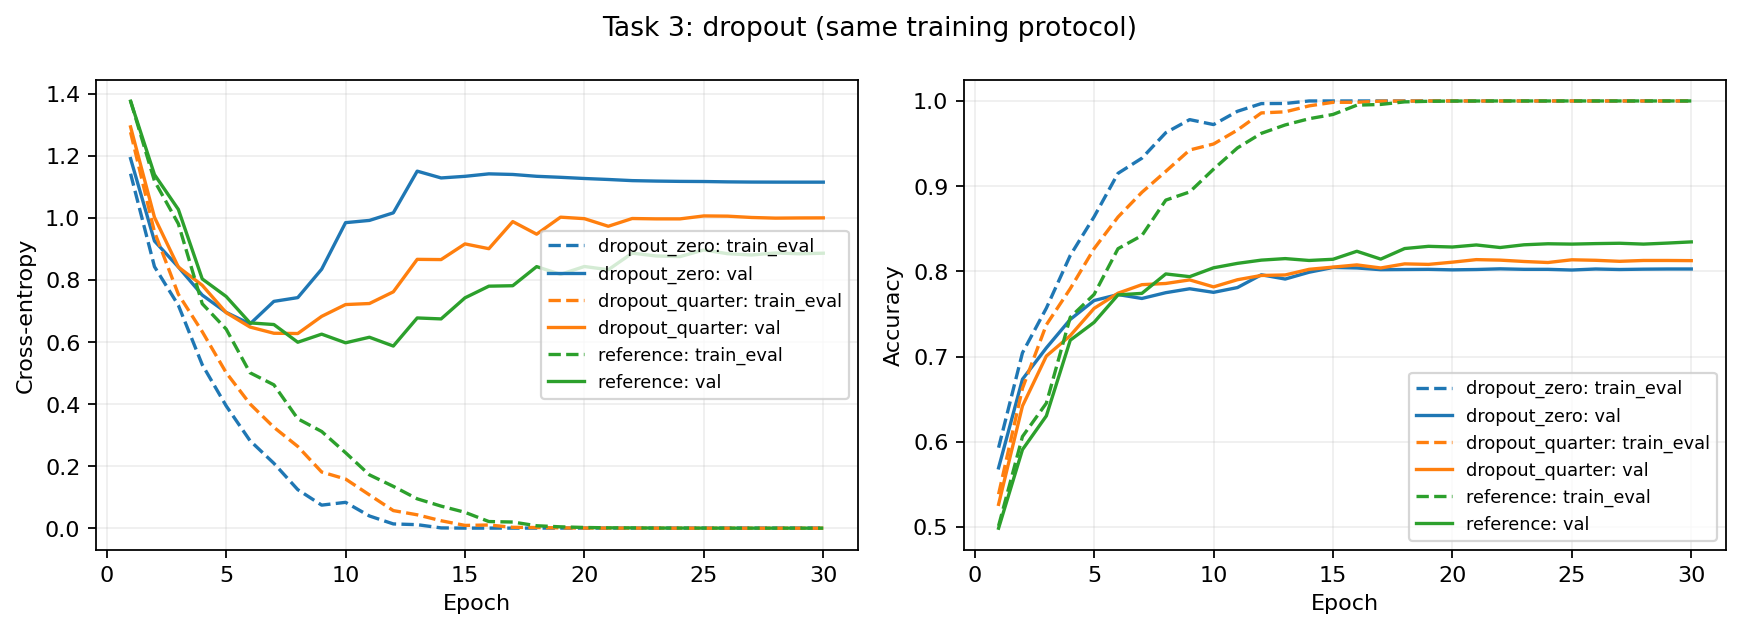

t3_l2.png


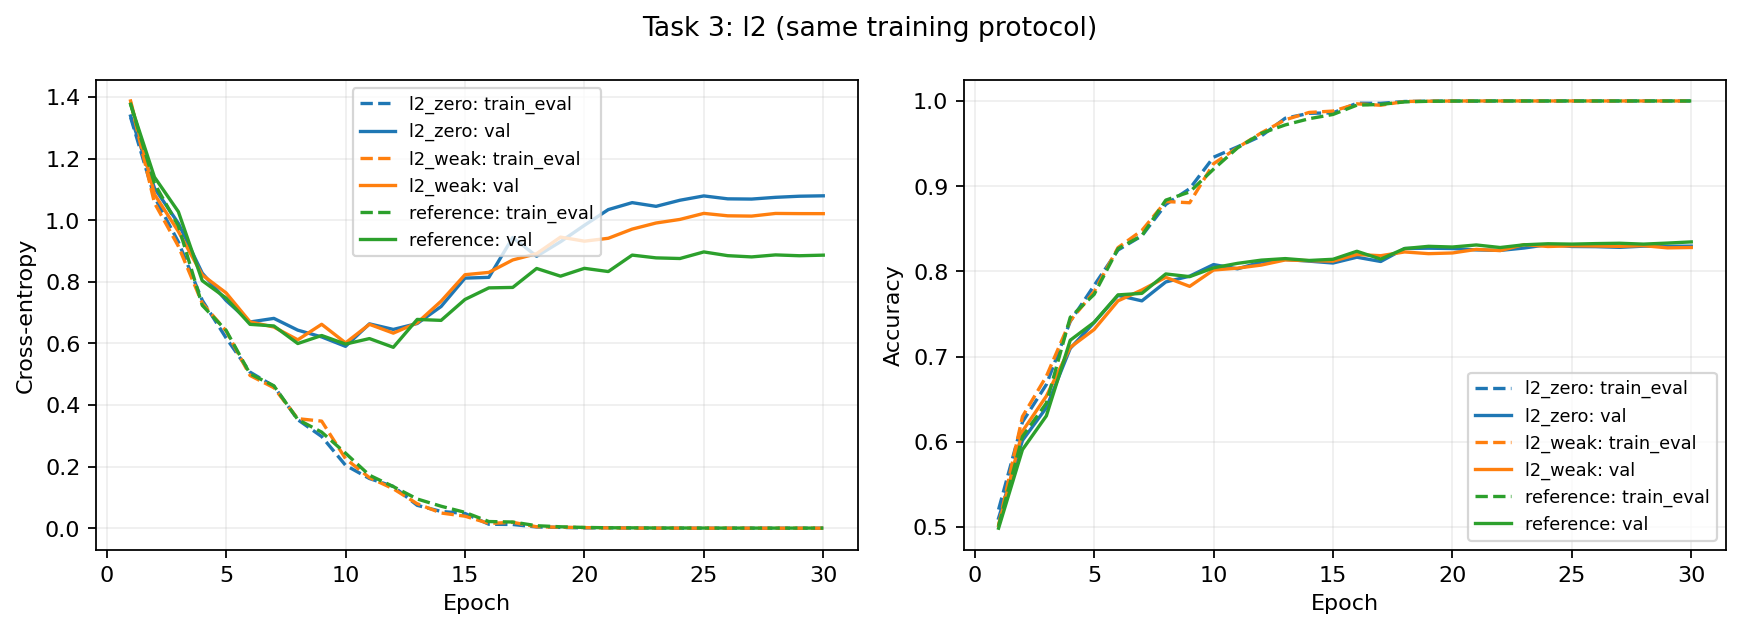

t5_fgsm_vs_random.png


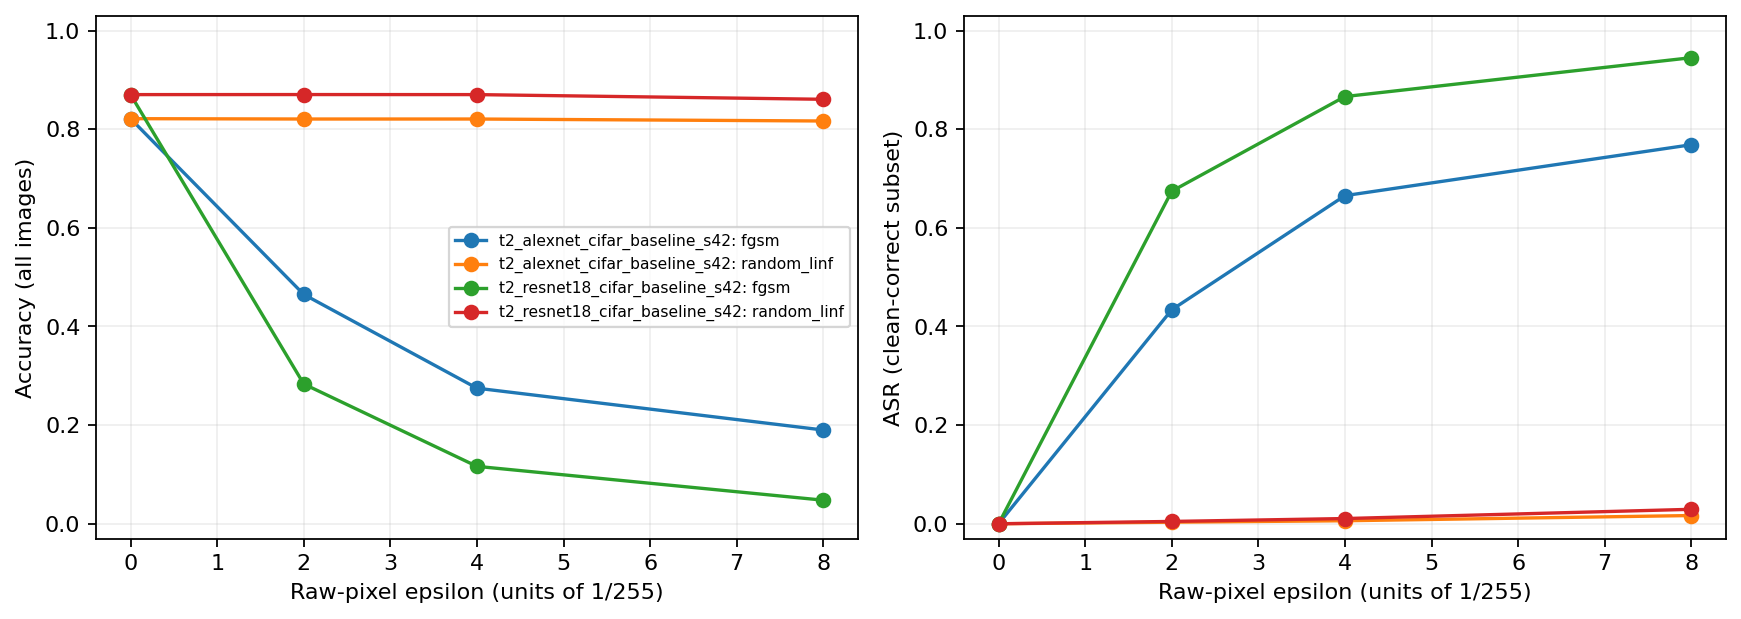

t5_t2_alexnet_cifar_baseline_s42_confusion.png


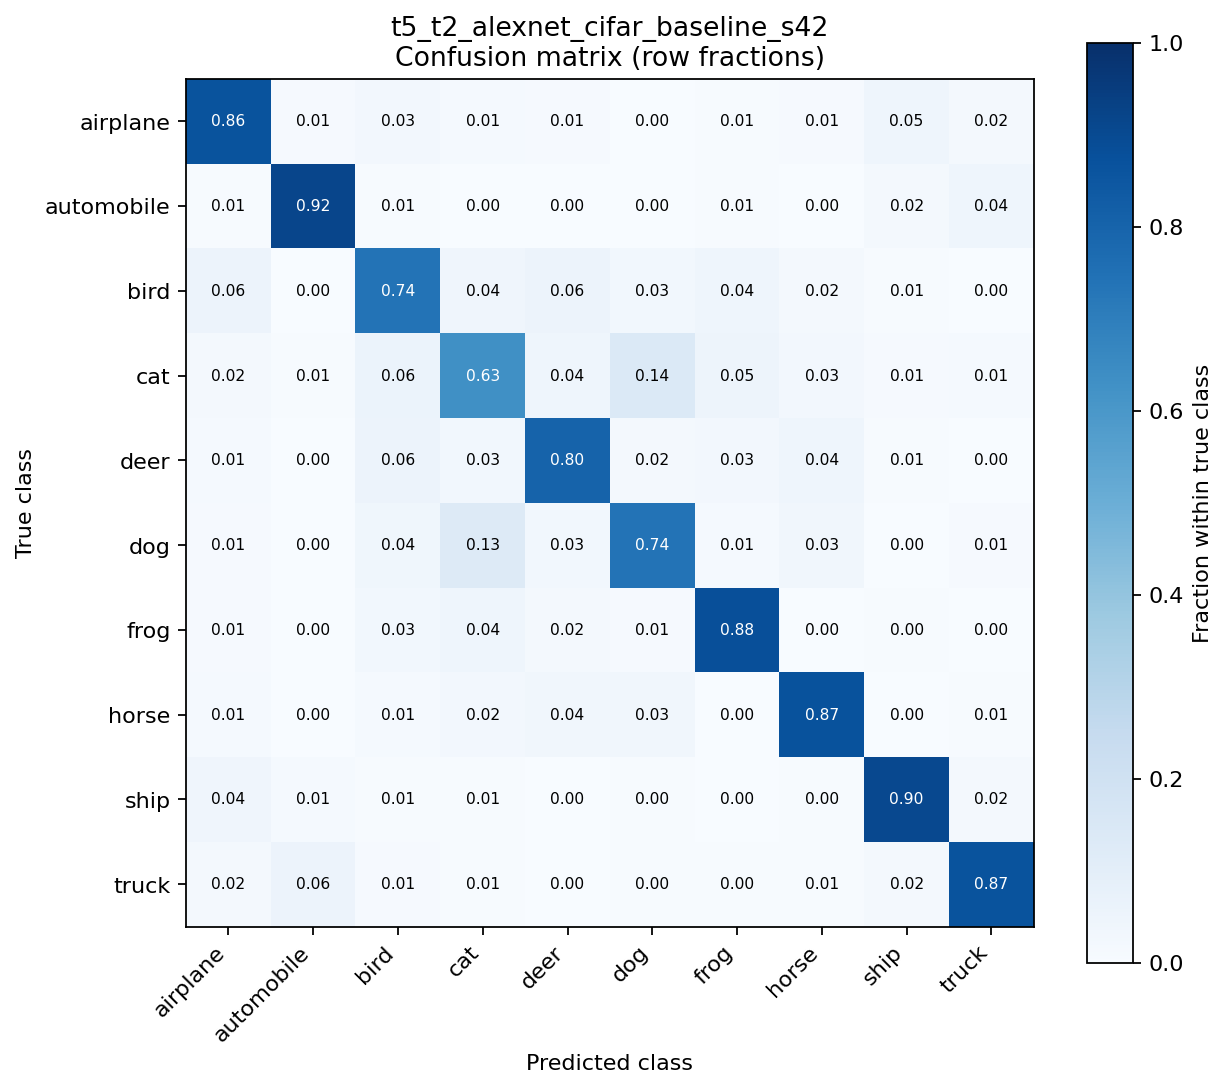

t5_t2_alexnet_cifar_baseline_s42_fgsm.png


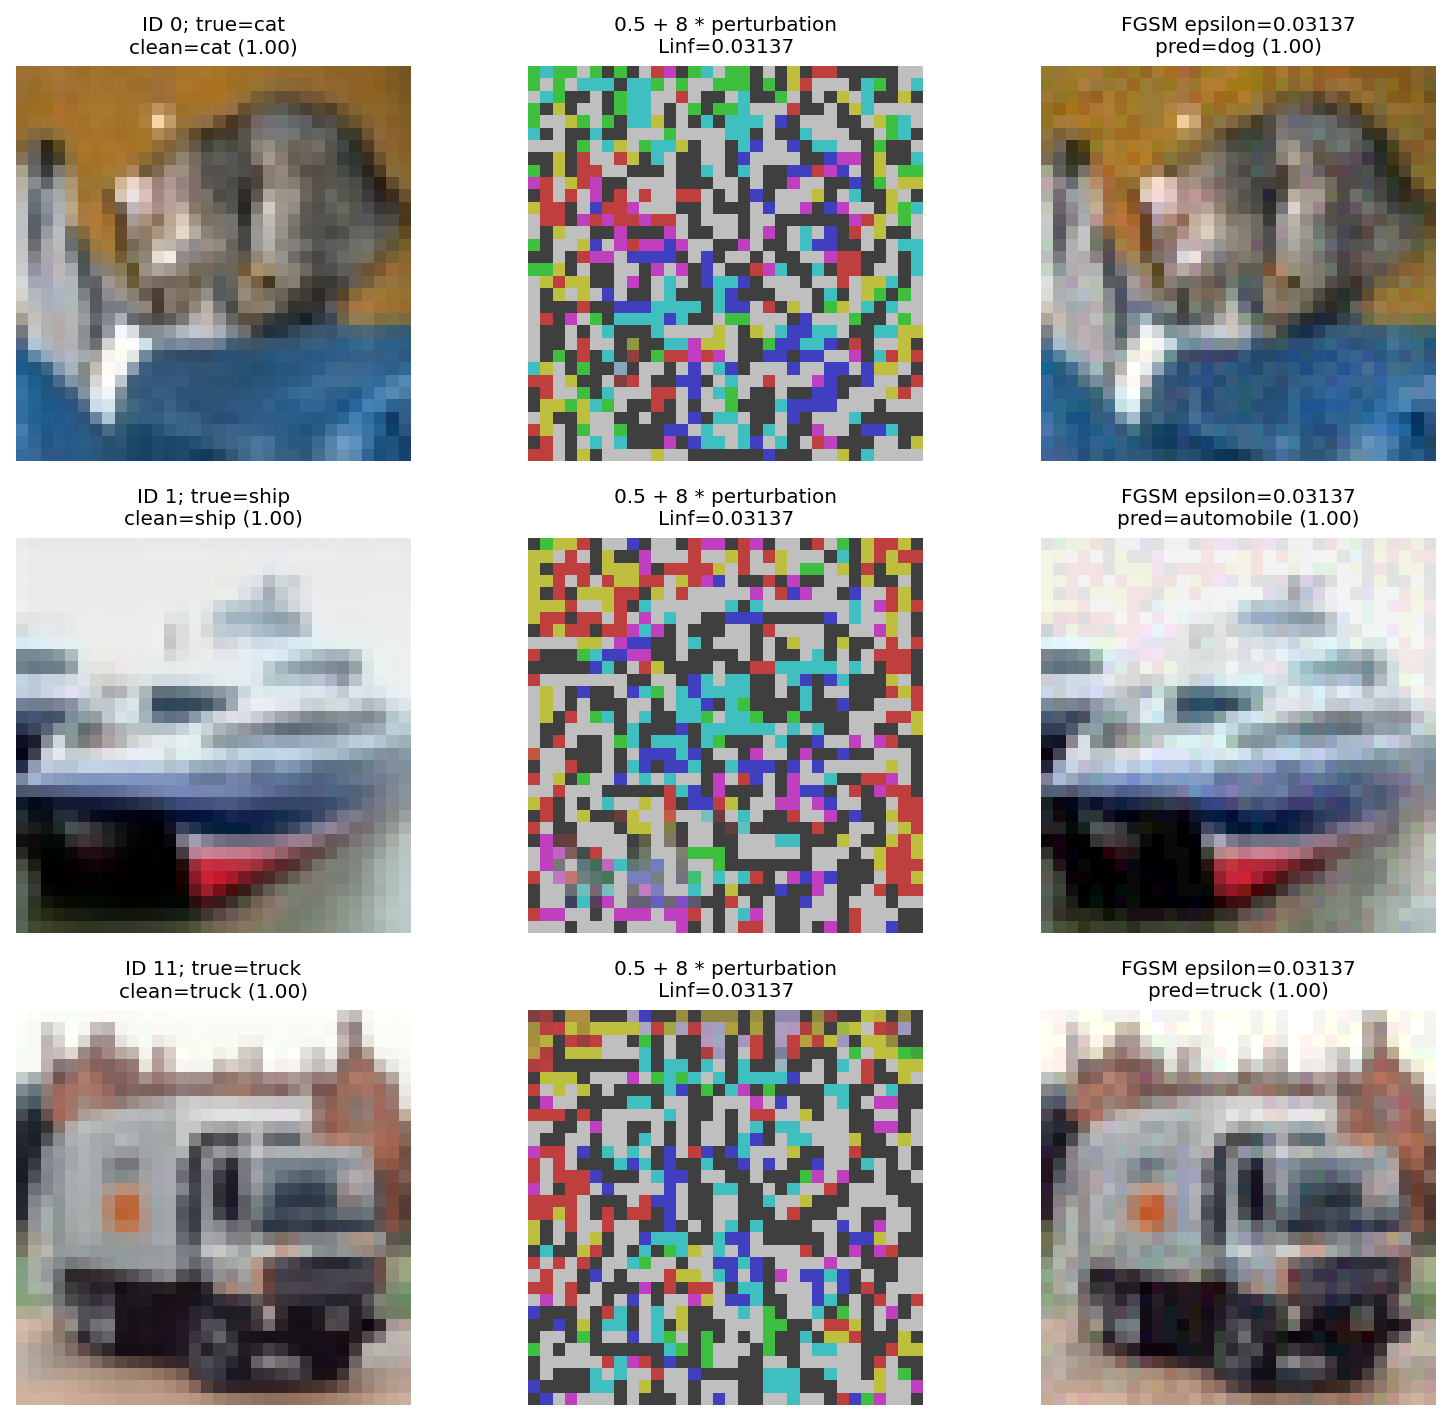

t5_t2_alexnet_cifar_baseline_s42_predictions.png


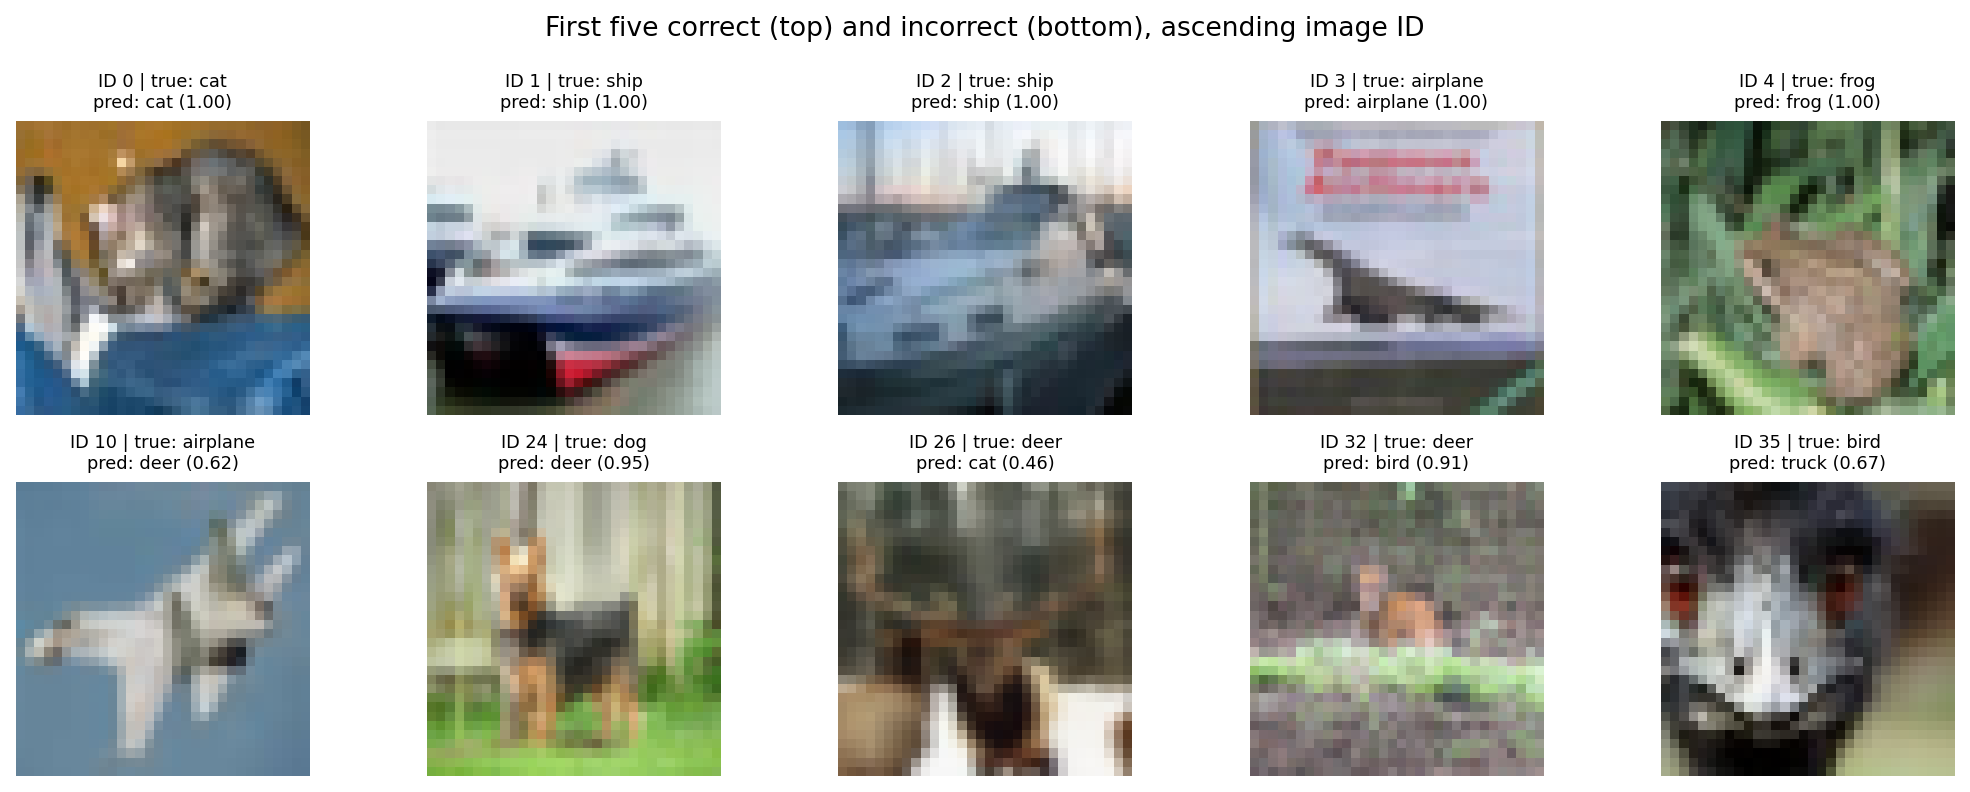

t5_t2_resnet18_cifar_baseline_s42_confusion.png


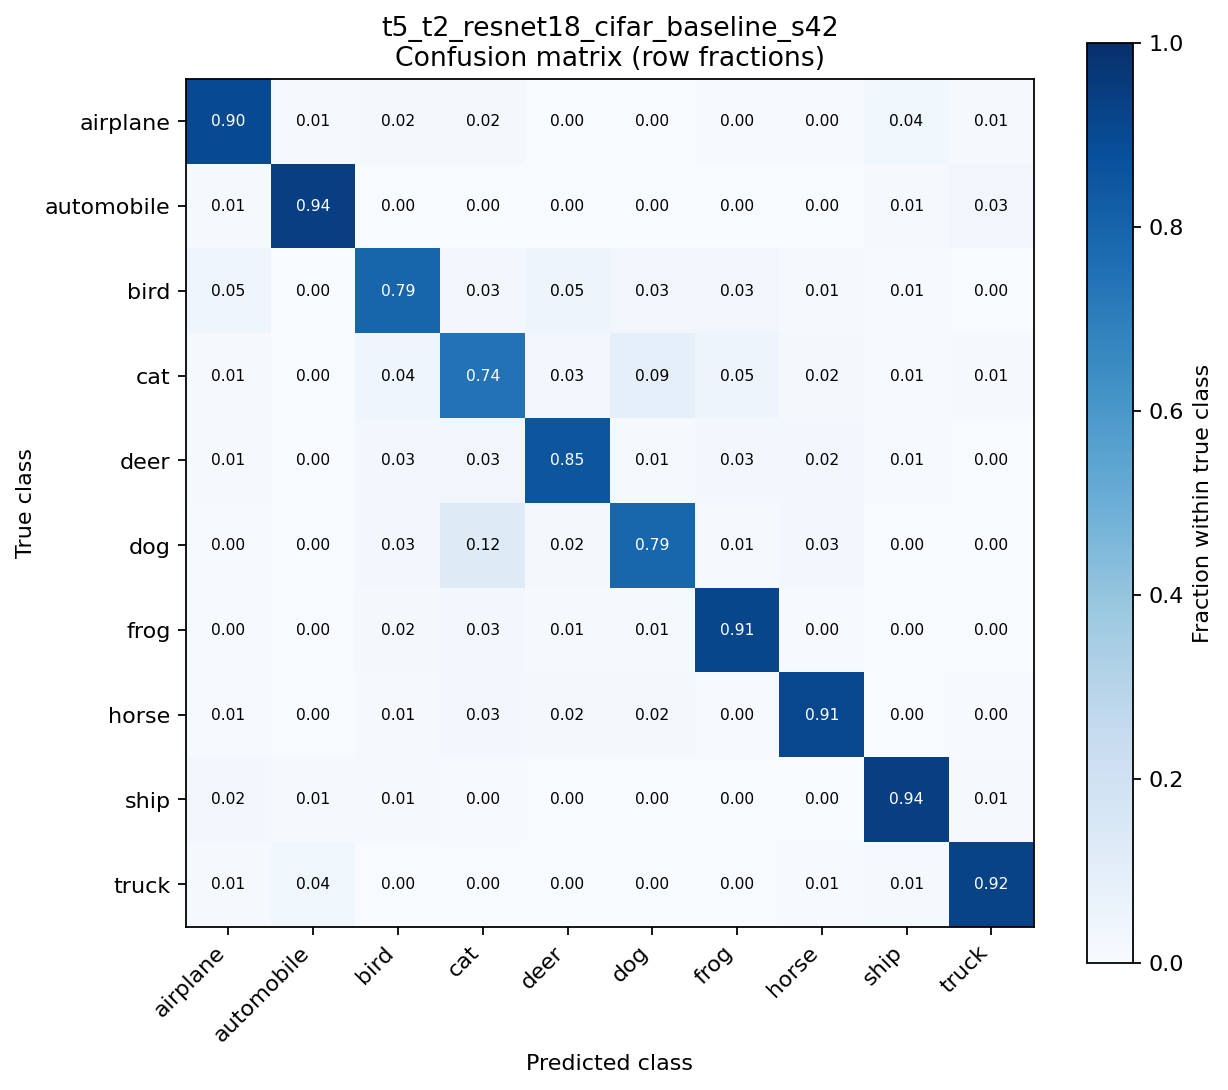

t5_t2_resnet18_cifar_baseline_s42_fgsm.png


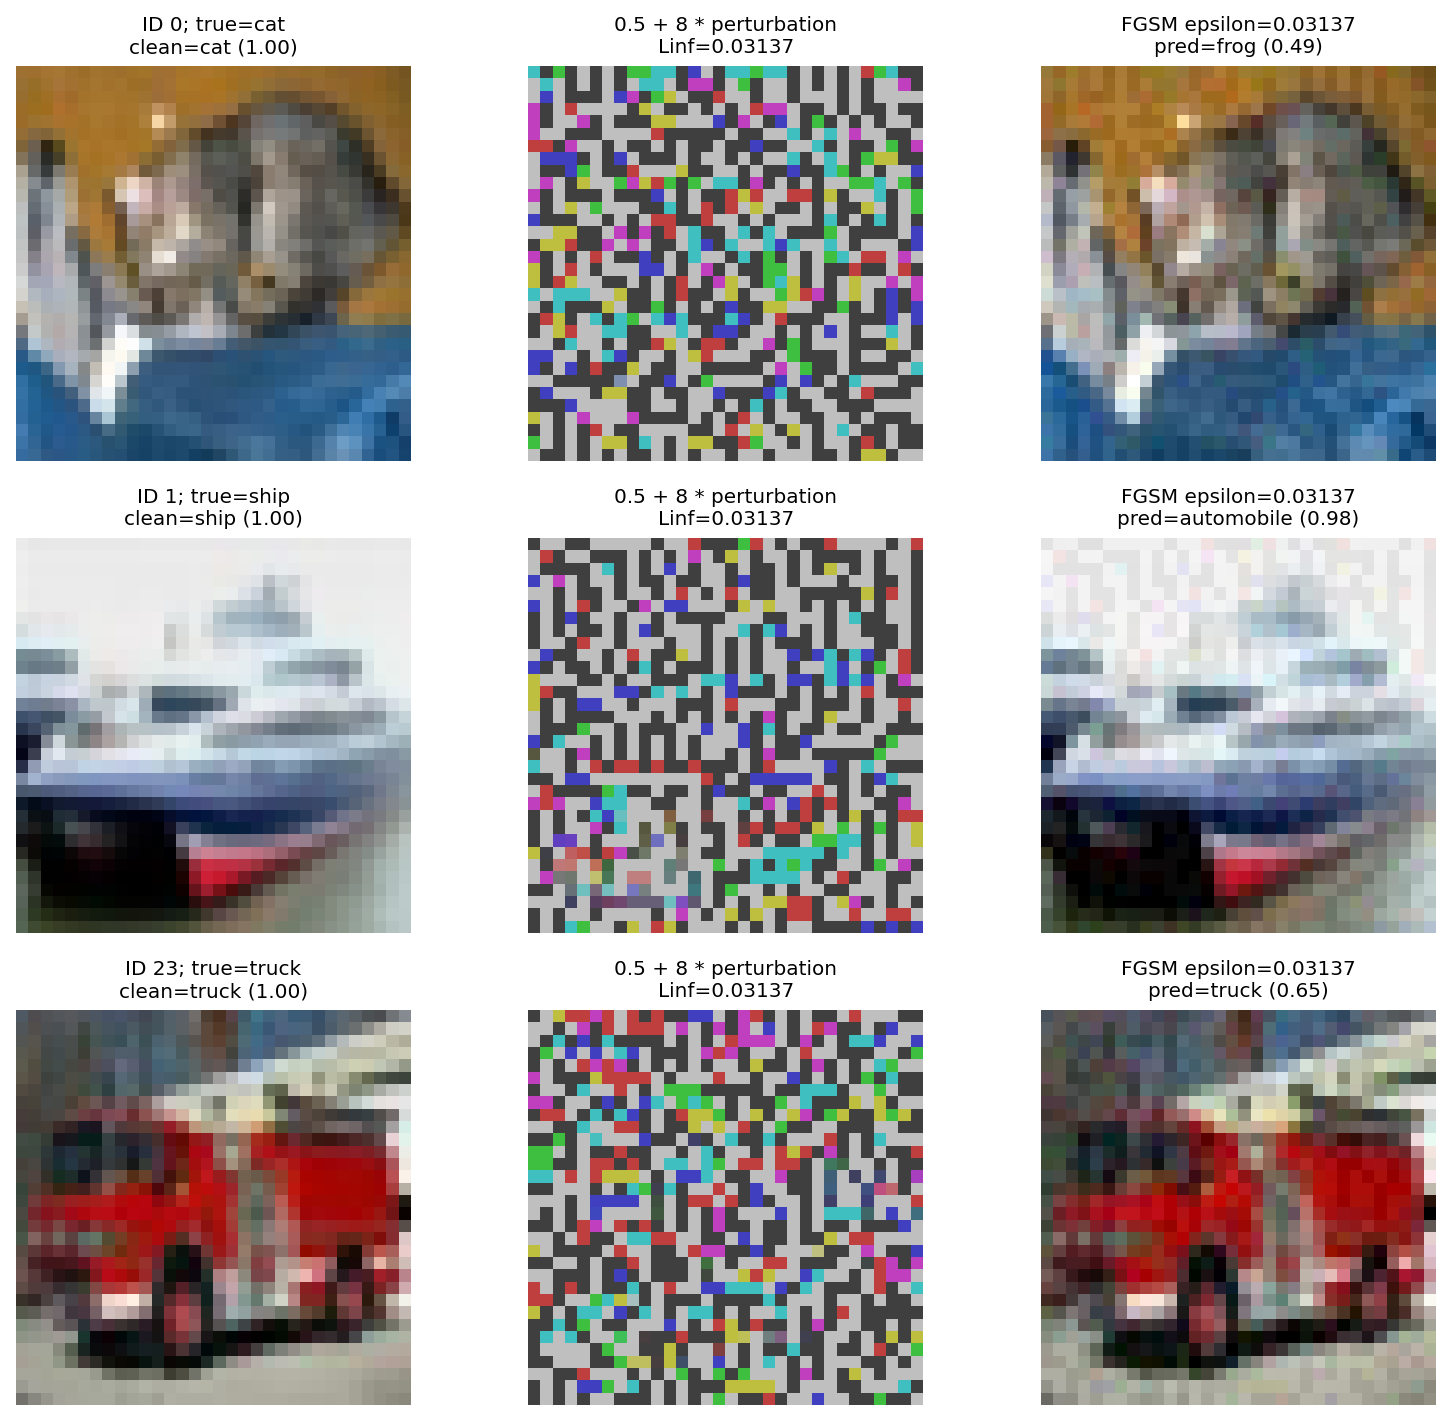

t5_t2_resnet18_cifar_baseline_s42_predictions.png


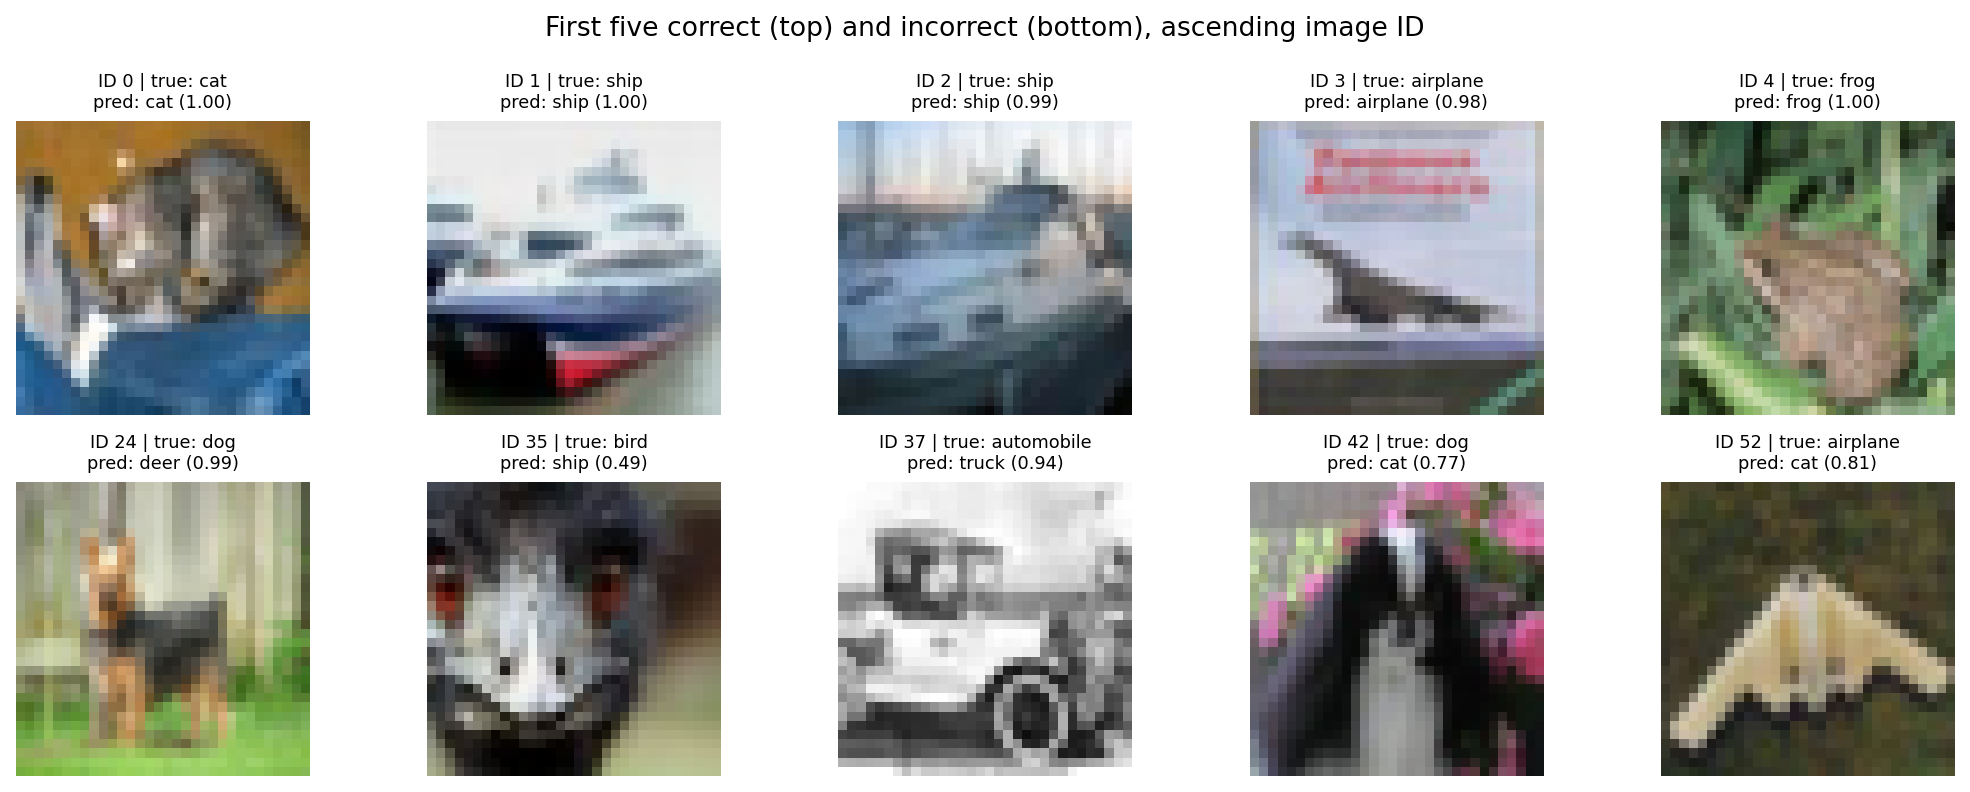

t5_training_diagnostics.png


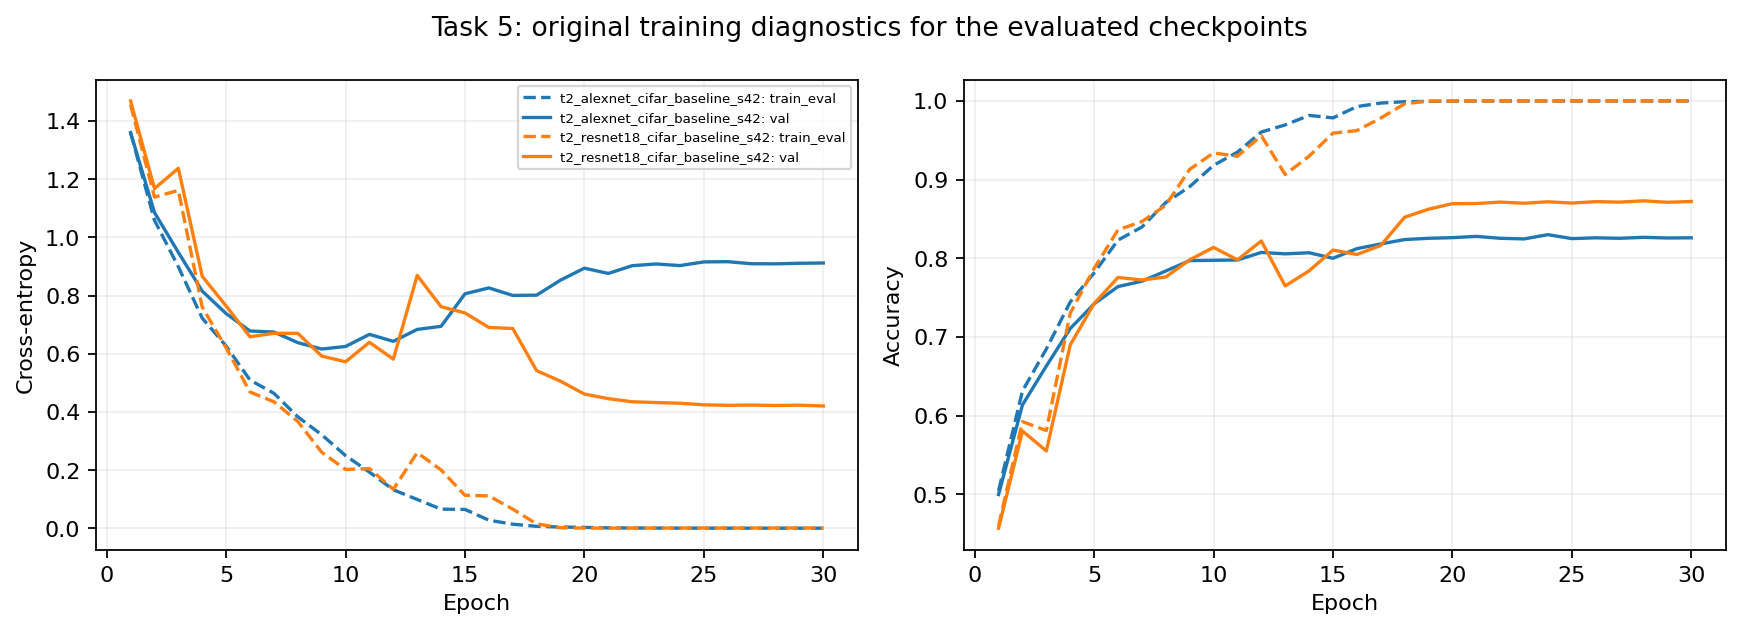

,class,precision,recall,f1-score,support
0,airplane,0.822243,0.865,0.843080,1000.0
1,automobile,0.906838,0.915,0.910901,1000.0
2,bird,0.749495,0.742,0.745729,1000.0
3,cat,0.682505,0.632,0.656282,1000.0
4,deer,0.803410,0.801,0.802203,1000.0
5,dog,0.751016,0.739,0.744960,1000.0
6,frog,0.855199,0.880,0.867422,1000.0
7,horse,0.856299,0.870,0.863095,1000.0
8,ship,0.887033,0.903,0.894945,1000.0
9,truck,0.885598,0.867,0.876200,1000.0


,class,precision,recall,f1-score,support
0,airplane,0.879293,0.896,0.887568,1000.0
1,automobile,0.938124,0.940,0.939061,1000.0
2,bird,0.834034,0.794,0.813525,1000.0
3,cat,0.737103,0.743,0.740040,1000.0
4,deer,0.861476,0.852,0.856712,1000.0
5,dog,0.816495,0.792,0.804061,1000.0
6,frog,0.872849,0.913,0.892473,1000.0
7,horse,0.904478,0.909,0.906733,1000.0
8,ship,0.923304,0.939,0.931086,1000.0
9,truck,0.931452,0.924,0.927711,1000.0


Validated six complete Task 3 runs and both full-test Task 5 evaluations.
/content/ScalableMlLab/role_b_results.zip
/content/ScalableMlLab/role_b_checkpoints.zip



In [4]:
import pandas as pd
from IPython.display import display, Image
RESULTS = ROOT / 'lab1/results'
display(pd.read_csv(RESULTS / 'role_b_task3_summary.csv'))
display(pd.read_csv(RESULTS / 'role_b_task5_clean.csv'))
display(pd.read_csv(RESULTS / 'role_b_task5_attacks.csv'))
for image_path in sorted((RESULTS / 'figures/role_b').glob('*.png')):
    print(image_path.name)
    display(Image(filename=str(image_path)))
for source_id in load_json(ROOT / 'lab1/configs/role_b_experiments.json')['prediction_models']:
    display(pd.read_csv(RESULTS / f't5_{source_id}_classes.csv'))
with zipfile.ZipFile('/content/role_b_finish.zip') as archive:
    archive.extractall(ROOT)
completed = subprocess.run([sys.executable, str(ROOT / 'lab1/scripts/export_role_b.py')], capture_output=True, text=True, check=True)
print(completed.stdout)


In [7]:
for name in ('role_b_results.zip', 'role_b_checkpoints.zip'):
    p = ROOT / name
    print(name, p.stat().st_size, 'bytes')

role_b_results.zip 8774267 bytes
role_b_checkpoints.zip 141377608 bytes


## Measured conclusions

All six Task 3 configurations completed 30 epochs on the same Tesla T4 (FP32; PyTorch 2.14.1+cu130). The full-width reference achieved 83.46% best validation accuracy and 82.66% test accuracy. Half width achieved 81.30% validation and 80.52% test accuracy, with 54.25% fewer parameters and 50.94% less measured training time. Its batch-one latency was 0.661 ms versus 0.647 ms, so a smaller model did not provide a measured single-image speedup.

Dropout 0, 0.25 and 0.5 produced best validation accuracies of 80.46%, 81.38% and 83.46%. All configurations approached perfect training fit while validation performance plateaued. The increasing validation cross-entropy, particularly without Dropout, supports overfitting. Weight decay 5e-4 gave the highest validation accuracy and lower validation cross-entropy than 0 or 1e-4; small L2 accuracy differences require multiple seeds to assess stability.

For Task 5, the actual frozen Role A checkpoints achieved 82.14% (AlexNet) and 87.02% (ResNet) clean test accuracy, with macro F1 0.8205 and 0.8699. Cat recall was lowest for both (63.2% / 74.3%); confusion matrices show substantial cat/dog confusion. Image 24 is a dog confidently predicted as deer by both models. The first-five example rule is fixed by image ID. Original Role A training histories, rather than Task 3 histories, are shown for these models.

At epsilon 8/255, FGSM reduced accuracy to 19.01% / 4.78% and gave ASR 76.86% / 94.51%. Equal-budget uniform random noise retained 81.67% / 86.07% accuracy (ASR 1.67% / 2.93%). This demonstrates sensitivity to gradient-directed perturbations under the stated constraint. The random control matches the maximum permitted change; FGSM and uniform random noise have different magnitude distributions within that bound. ResNet's higher clean accuracy did not yield better resistance to this particular white-box attack.

Attack panels include successes and failures: image 0 changes from cat to dog for AlexNet and cat to frog for ResNet; image 1 changes from ship to automobile for both. AlexNet image 11 and ResNet image 23 remain truck. The central perturbation panel is amplified only for display. Failure of single-step FGSM does not certify robustness; iterative attacks with restarts are a useful follow-up.

## Reproducibility and scope

The repository's 34 tests passed locally. Five Role B tests and a separate 128-train/64-validation one-epoch smoke test passed on T4 before the full runs. Final measurements use all 45,000 training / 5,000 validation / 10,000 test images. Each Task 3 run processed 1,350,000 training examples. This experiment uses one seed and a 30-epoch budget. Timing comparisons apply to the same hardware/procedure: 10 warmups and 50 measured model forwards exclude preprocessing and transfers.

The execution used base revision d2eec8535fe105becf4ba035ce5fb762c57a687c plus the new Role B snapshot, identified by per-file SHA256 in the results. The base revision alone does not contain the new modules. Role A checkpoint source revision is b1f9a7e. Complete Python modules and frozen configurations accompany this executed notebook in the source/results bundle. Use role_b_reproduce.ipynb for a fresh run; this notebook preserves the actual run and outputs.

## References

- [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html)
- [AlexNet (2012)](https://proceedings.neurips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html)
- [ResNet](https://arxiv.org/abs/1512.03385)
- [Dropout](https://jmlr.org/papers/v15/srivastava14a.html)
- [FGSM: Explaining and Harnessing Adversarial Examples](https://arxiv.org/abs/1412.6572)
- [Team repository, shared modules and experiment contract](https://github.com/Mrpooool/ScalableMlLab)


In [13]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
from pathlib import Path
import shutil, hashlib
EXPORT = Path('/content/drive/MyDrive/Role_B_Results')
EXPORT.mkdir(parents=True, exist_ok=True)
for name in ('role_b_results.zip', 'role_b_checkpoints.zip'):
    source = ROOT / name
    destination = EXPORT / name
    shutil.copy2(source, destination)
    assert hashlib.sha256(source.read_bytes()).hexdigest() == hashlib.sha256(destination.read_bytes()).hexdigest()
    print('SAVED', destination, destination.stat().st_size, hashlib.sha256(destination.read_bytes()).hexdigest())

Mounted at /content/drive
SAVED /content/drive/MyDrive/Role_B_Results/role_b_results.zip 8774267 3a878eb5b2457c9db20aef3134d5ed27e40cc7bbae99217039a0ae679774821b
SAVED /content/drive/MyDrive/Role_B_Results/role_b_checkpoints.zip 141377608 147a0699959623c7b423addd8e5aedca12a52d084c97201fc2df81500e6cb3e5


## Paired ordinary-corruption results

This table was added locally from the saved T4 JSON artifacts after recovery. All original executed cells and outputs are preserved. It uses the same Role A weights and image IDs as FGSM. Corruption families have different severity definitions.

| Condition | AlexNet accuracy % | ResNet accuracy % |
|---|---:|---:|
| rotation_15deg | 70.17 | 78.70 |
| translation_3px | 70.56 | 81.00 |
| gaussian_noise_std_0_05 | 77.20 | 73.86 |